<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">Timestamped Soccer World All-in-One: 90 Competitions — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The key figures of the listing, recomputed from the files of the full product:
197,615 matches from 90 competitions (the top division of 66 countries, six
second divisions, 18 international competitions), 353,573,942 timestamped quotes from 5
named bookmakers incl. Pinnacle, 10,835,875 snapshots from 37 more bookmakers, 2016–2026.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing,
recomputes it from the files and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data. It reads 354 million quotes:
allow a few minutes.

⚽ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/ylkgqx?utm_source=github&utm_medium=notebook&utm_campaign=all_in_one_premium&utm_content=notebook_top)** · free 20-match sample: same tables, same columns.

## 0 · Setup

In [1]:
import os, glob, hashlib, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

def find_root():
    """Folder of the full product: the Ultimate_Matches.csv with the most rows wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("ULT_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += glob.glob(os.path.join(base, "**", "Ultimate_Matches.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError("Ultimate_Matches.csv not found: attach the dataset to this notebook")
    return os.path.dirname(max(hits, key=os.path.getsize))

ROOT = find_root()
print("Product folder:", ROOT)

def table_files(prefix):
    """The 90 per-competition files of a table, wherever they sit under the product folder:
    .csv.gz as shipped, or .csv when the hosting platform stores them decompressed."""
    for ext in (".csv.gz", ".csv"):
        # files only: Kaggle stores each decompressed .csv.gz as a folder "X.csv" that holds the file "X.csv"
        hits = sorted(p for p in glob.glob(os.path.join(ROOT, "**", prefix + "*" + ext), recursive=True)
                      if os.path.isfile(p))
        if hits:
            return hits
    return []

def stem(path):
    """File name without folder or extension: the key of the MANIFEST row counts."""
    b = os.path.basename(path)
    return b[:-7] if b.endswith(".csv.gz") else b.rsplit(".", 1)[0]

FILES = {t: table_files(p) for t, p in (("odds", "Ultimate_Odds_Timestamped_"),
                                        ("snapshots", "Ultimate_Bookmaker_Snapshots_"),
                                        ("events", "Ultimate_Events_"), ("lineups", "Ultimate_Lineups_"),
                                        ("minute_stats", "Ultimate_Minute_Stats_"))}
for t, fs in FILES.items():
    kinds = sorted({".csv.gz" if f.endswith(".gz") else ".csv" for f in fs}) or ["none found"]
    print(f"{t:13} {len(fs):>2} files  ({', '.join(kinds)})")
assert all(len(fs) == 90 for fs in FILES.values()), \
    "each table should have 90 files, one per competition: is the dataset fully processed on this platform?"

# Olivier Sports Data dark signature. HDA = home / draw / away, checked for colour-blind and normal-vision
# separation on this background.
BG, FG, FG2, GRID, CYAN = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff"
HDA = {"Home": "#00a3cc", "Draw": "#c98500", "Away": "#d55181"}
BOOK_COLOR = {"Bet365": "#00d4ff", "Pinnacle": "#f0c75e", "Unibet": "#7bd88f", "Betfair": "#d55181", "Betsson": "#b59cff"}
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": FG2, "xtick.color": FG2, "ytick.color": FG2,
    "text.color": FG, "axes.titlecolor": FG, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110,
})

RESULTS = []
def check(claim, ok, detail=""):
    RESULTS.append((claim, bool(ok), detail))
    print(("PASS  " if ok else "FAIL  ") + claim + (f"   [{detail}]" if detail else ""))

def epoch(s):
    """ISO 8601 UTC 'YYYY-MM-DDTHH:MM:SSZ' -> Unix seconds (NaN when empty)."""
    t = pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%SZ", utc=True, errors="coerce")
    return (t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()

def read(path, cols):
    try:
        d = pd.read_csv(path, usecols=cols, engine="pyarrow")   # fast, multi-threaded
    except Exception:
        d = pd.read_csv(path, usecols=cols)
    for c in d.columns:   # the pyarrow reader turns ISO times into datetimes: show them as written in the file
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    return d

BOOKS = ["Bet365", "Pinnacle", "Unibet", "Betfair", "Betsson"]

Product folder: /kaggle/input/datasets/oliviersportsdata/world-football-odds-incl-pinnacle-full/Timestamped_Soccer_World_All-in-One_Premium_2016-2026
odds          90 files  (.csv)
snapshots     90 files  (.csv)
events        90 files  (.csv)
lineups       90 files  (.csv)
minute_stats  90 files  (.csv)


## 1 · The claims

Copied from the listing and the README. Nothing below is adjusted to fit: if the files disagree, the cell prints FAIL.
`PACKS` lists the competitions of each of the five packs merged in this product.

In [2]:
CLAIMS = {
    'matches': 197_615,
    'competitions': 90,
    'domestic_leagues': 72,
    'countries': 66,
    'second_divisions': 6,
    'international_competitions': 18,
    'competition_seasons': 898,
    'first_kickoff_on': '2016-08-28',
    'last_kickoff_before': '2026-10-01T00:00:00Z',
    'matches_per_pack': {
        'Big 6 Europe Premium': 45_554, 'Other European Leagues Premium': 92_615,
        'International Football Premium': 11_118, 'Futbol, Futebol & Soccer Premium': 30_999,
        'Timestamped Soccer Asia & Africa Premium': 17_329,
    },
    'matches_per_competition': {
        'AFC_ASIA': 102, 'AFC_CL': 1_142, 'ALB': 1_649, 'ALG': 2_536, 'ARG': 4_717, 'ARM': 1_399, 'AUT': 1_934,
        'AZE': 1_398, 'BEL': 2_982, 'BIH': 1_876, 'BLR': 2_354, 'BOL': 2_803, 'BRA': 3_866, 'BUL': 2_594,
        'CAF_AFCON': 240, 'CAF_CL': 1_414, 'CHI': 2_147, 'CHN': 2_341, 'COL': 4_098, 'CONCACAF': 364, 'COPA_AM': 86,
        'CRO': 1_814, 'CYP': 2_303, 'CZE': 2_774, 'DEN': 2_172, 'ECU': 2_645, 'ENG_CH': 5_605, 'ENG_PL': 3_822,
        'ESP_LL': 3_853, 'ESP_SEG': 4_728, 'EST': 1_755, 'EURO_2020': 51, 'EURO_2024': 51, 'FIFA_CWC': 125,
        'FIN': 1_759, 'FRA_L1': 3_512, 'FRA_L2': 3_585, 'FRO': 1_274, 'GEO': 1_735, 'GER_BL': 3_108,
        'GER_BL2': 3_107, 'GRE': 2_434, 'HUN': 1_984, 'IRL': 1_768, 'ISL': 1_459, 'ISR': 2_416, 'ITA_SA': 3_837,
        'ITA_SB': 4_062, 'JPN': 3_324, 'KAZ': 1_839, 'KOR': 2_230, 'KSA': 2_535, 'LIBERTA': 1_246, 'LTU': 1_519,
        'LUX': 2_159, 'LVA': 1_492, 'MAR': 2_403, 'MDA': 1_149, 'MEX': 3_347, 'MKD': 1_825, 'MLT': 1_831,
        'MNE': 1_808, 'NED': 3_100, 'NIR': 2_271, 'NOR': 2_415, 'POL': 2_976, 'POR_PL': 3_112, 'POR_SL': 3_223,
        'ROU': 3_035, 'RUS': 2_458, 'SCO': 2_304, 'SRB': 3_019, 'SUDAM': 1_401, 'SUI': 1_970, 'SVK': 1_926,
        'SVN': 1_809, 'SWE': 2_422, 'TUN': 1_960, 'TUR': 3_402, 'UEFA_CL': 1_390, 'UEFA_ECL': 729, 'UEFA_EL': 1_833,
        'UEFA_NL': 712, 'UKR': 2_073, 'USA': 4_589, 'VEN': 2_787, 'WAL': 1_980, 'WC_2018': 64, 'WC_2022': 64,
        'WC_2026': 104,
    },
    'extra_time': 355,
    'penalty_shootouts': 516,
    'matches_with_leg': 5_009,
    'neutral_venue': {'neutral': 1_228, 'home_country': 186_524, 'unknown': 9_863},
    'round_filled': 182_496,
    'quotes': 353_573_942,
    'in_play': 263_916_151,
    'pre_match': 89_657_791,
    'quotes_per_book': {
        'Bet365': 250_606_072, 'Pinnacle': 17_177_038, 'Unibet': 23_263_098, 'Betfair': 54_134_487,
        'Betsson': 8_393_247,
    },
    'ft_1x2_close_per_book': {
        'Bet365': 191_146, 'Pinnacle': 145_004, 'Unibet': 166_824, 'Betfair': 37_412, 'Betsson': 73_034,
    },
    'first_close_per_market': {
        'Bet365': {'FT_1X2': '2016-08-28', 'FT_Asian_Handicap': '2016-08-28', 'FT_Total_Goals': '2016-08-28', 'FT_Total_Corners': '2019-10-13', 'HT_1X2': '2018-01-10', 'HT_Asian_Handicap': '2019-10-13', 'HT_Total_Goals': '2016-12-10', 'HT_Total_Corners': '2016-12-10'},
        'Pinnacle': {'FT_1X2': '2018-09-27', 'FT_Asian_Handicap': '2023-06-23', 'FT_Total_Goals': '2018-09-27'},
        'Unibet': {'FT_1X2': '2017-04-15', 'FT_Total_Goals': '2017-04-15'}, 'Betfair': {'FT_1X2': '2023-11-03'},
        'Betsson': {'FT_1X2': '2022-07-03', 'FT_Total_Goals': '2022-07-03'},
    },
    'median_close_gap': {
        'Bet365': '25 min', 'Betfair': '6 min', 'Betsson': '10 min', 'Pinnacle': '4 min', 'Unibet': '1.8 h',
    },
    'coverage_from': {
        'Bet365': '2016-08-28', 'Pinnacle': '2018-09-27', 'Unibet': '2017-04-15', 'Betfair': '2023-11-03',
        'Betsson': '2022-07-03', 'Minute_Stats': '2017-06-10', 'Events': '2016-08-28',
    },
    'coverage_gaps': {
        'Bet365': [], 'Pinnacle': [['2023-09', '2023-11'], ['2026-07', '2026-08']],
        'Unibet': [['2026-07', '2026-08']], 'Betfair': [['2024-11', '2025-08'], ['2026-07', '2026-08']],
        'Betsson': [['2026-06', '2026-08']], 'Minute_Stats': [['2018-01', '2019-09'], ['2026-06', '2026-07']],
        'Events': [],
    },
    'coverage_stops': {
        'Bet365': {'BLR': '2021-11-28', 'RUS': '2022-03-07'}, 'Pinnacle': {},
        'Unibet': {'BLR': '2021-11-28', 'MNE': '2022-05-20', 'RUS': '2022-03-07'}, 'Betfair': {}, 'Betsson': {},
        'Minute_Stats': {'BLR': '2021-11-28', 'RUS': '2022-02-28'},
        'Events': {'BLR': '2021-11-28', 'RUS': '2022-02-28'},
    },
    'snapshots': 10_835_875,
    'snapshot_books': 37,
    'snapshot_matches': 188_855,
    'snapshot_books_per_match': 13.9,
    'team_stats': 395_230,
    'team_stat_metrics': 29,
    'lineups': 5_478_267,
    'events': 5_220_292,
    'event_types': 13,
    'minute_stats': 49_494_435,
    'lineups_share_per_pack': {
        'Big 6 Europe Premium': 98, 'Other European Leagues Premium': 55, 'International Football Premium': 85,
        'Futbol, Futebol & Soccer Premium': 79, 'Timestamped Soccer Asia & Africa Premium': 48,
    },
    'minute_stats_time': {
        'from': '2021-05-10', 'matches_without': 38_948, 'rows_without': 14_262_144, 'clean_border': True,
    },
    'example_in_play_bet365_1x2': 168,
    'example_quotes_all_books': 3_207,
}
PACKS = {
    'Big 6 Europe Premium': ['ENG_PL', 'ENG_CH', 'ESP_LL', 'ESP_SEG', 'ITA_SA', 'ITA_SB', 'GER_BL', 'GER_BL2', 'FRA_L1', 'FRA_L2', 'POR_PL', 'POR_SL'],
    'Other European Leagues Premium': ['ALB', 'ARM', 'AUT', 'AZE', 'BEL', 'BIH', 'BLR', 'BUL', 'CRO', 'CYP', 'CZE', 'DEN', 'EST', 'FIN', 'FRO', 'GEO', 'GRE', 'HUN', 'IRL', 'ISL', 'ISR', 'KAZ', 'LTU', 'LUX', 'LVA', 'MDA', 'MKD', 'MLT', 'MNE', 'NED', 'NIR', 'NOR', 'POL', 'ROU', 'RUS', 'SCO', 'SRB', 'SUI', 'SVK', 'SVN', 'SWE', 'TUR', 'UKR', 'WAL'],
    'International Football Premium': ['UEFA_CL', 'UEFA_EL', 'UEFA_ECL', 'UEFA_NL', 'EURO_2020', 'EURO_2024', 'WC_2018', 'WC_2022', 'WC_2026', 'FIFA_CWC', 'LIBERTA', 'SUDAM', 'COPA_AM', 'CONCACAF', 'AFC_CL', 'AFC_ASIA', 'CAF_CL', 'CAF_AFCON'],
    'Futbol, Futebol & Soccer Premium': ['ARG', 'BOL', 'BRA', 'CHI', 'COL', 'ECU', 'MEX', 'USA', 'VEN'],
    'Timestamped Soccer Asia & Africa Premium': ['ALG', 'CHN', 'JPN', 'KOR', 'KSA', 'MAR', 'TUN'],
}

## 2 · Every file is the one that was shipped

`MANIFEST.csv` lists each file with its row count and SHA-256 fingerprint. Recomputing the fingerprints proves
that nothing was altered between the build and this notebook.

In [3]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"), dtype=str)
located = {}
for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True):
    if os.path.isfile(p):
        located.setdefault(os.path.basename(p), p)
t0, missing, altered, decompressed, hashed = time.time(), [], [], [], 0
for f, h in zip(man["File"], man["SHA256"]):
    p = os.path.join(ROOT, *f.split("/"))
    if not os.path.exists(p):
        p = located.get(os.path.basename(f))
    if p is None and f.endswith(".gz") and os.path.basename(f)[:-3] in located:
        decompressed.append(f); continue
    if p is None:
        missing.append(f); continue
    d = hashlib.sha256()
    with open(p, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 22), b""):
            d.update(block)
    hashed += os.path.getsize(p)
    if d.hexdigest() != h:
        altered.append(f)
print(f"{len(man)} files, {hashed / 1e9:.2f} GB hashed in {time.time() - t0:.1f} s")
check(f"all {len(man)} files present", not missing, ", ".join(missing[:5]))
check("every SHA-256 matches the MANIFEST" + (" (files kept compressed)" if decompressed else ""),
      not altered and not missing, ", ".join(altered[:5]))
if decompressed:
    print(f"Note: {len(decompressed)} .csv.gz files are stored decompressed (.csv) on this platform, so their compressed "
          "fingerprint cannot match. Their row counts are checked file by file against the MANIFEST below.")
man["Rows"] = pd.to_numeric(man["Rows"], errors="coerce")
ROWS = {stem(f): int(r) for f, r in zip(man["File"], man["Rows"]) if pd.notna(r)}
def table_of(path):
    """Table of a listed file: the per-competition files of a folder count as one table."""
    b = re.sub(r"\.(csv\.gz|csv|xlsx|md)$", "", path.split("/")[-1])
    for t in ("Odds_Timestamped", "Bookmaker_Snapshots", "Events", "Lineups", "Minute_Stats"):
        if "/" in path and b.startswith(f"Ultimate_{t}_"):
            return f"Ultimate_{t}"
    return b

groups = man.assign(Table=man["File"].map(table_of))
groups.groupby("Table").agg(files=("File", "size"), rows=("Rows", "sum")).astype(int)

459 files, 0.47 GB hashed in 13.5 s
PASS  all 459 files present
PASS  every SHA-256 matches the MANIFEST (files kept compressed)
Note: 450 .csv.gz files are stored decompressed (.csv) on this platform, so their compressed fingerprint cannot match. Their row counts are checked file by file against the MANIFEST below.


,files,rows
Table,,
README,1,0
Ultimate_Bookmaker_Snapshots,90,10835875
Ultimate_Coverage,2,898
Ultimate_Events,90,5220292
Ultimate_Lineups,90,5478267
Ultimate_Matches,2,197615
Ultimate_Minute_Stats,90,49494435
Ultimate_Odds_Timestamped,90,353573942
Ultimate_Opening_Closing_Odds,2,197615


## 3 · Matches

In [4]:
M = pd.read_csv(os.path.join(ROOT, "Ultimate_Matches.csv"), low_memory=False,
                dtype={"Match_ID": str, "Home_Team_ID": str, "Away_Team_ID": str, "Season": str, "Country": str,
                       "Home_Formation": str, "Away_Formation": str})
PACK_OF = {c: p for p, cs in PACKS.items() for c in cs}
M["Pack"] = M["Competition_Code"].map(PACK_OF)
check(f"{CLAIMS['matches']:,} matches", len(M) == CLAIMS["matches"], f"{len(M):,}")
check("Match_ID is unique across the five packs", M["Match_ID"].is_unique)
check("every competition belongs to one of the five packs", M["Pack"].notna().all())
dom = M[M["Country"].notna()]
seasons = M[["Competition_Code", "Season"]].drop_duplicates()
got = (M["Competition_Code"].nunique(), dom["Competition_Code"].nunique(), dom["Country"].nunique(),
       dom.loc[dom["Division"] == 2, "Competition_Code"].nunique(), M.loc[M["Country"].isna(), "Competition_Code"].nunique())
check(f"{CLAIMS['competitions']} competitions: {CLAIMS['domestic_leagues']} domestic leagues in {CLAIMS['countries']} "
      f"countries ({CLAIMS['second_divisions']} second divisions) and {CLAIMS['international_competitions']} international "
      f"competitions; {CLAIMS['competition_seasons']} competition-seasons",
      got == (CLAIMS["competitions"], CLAIMS["domestic_leagues"], CLAIMS["countries"], CLAIMS["second_divisions"],
              CLAIMS["international_competitions"]) and len(seasons) == CLAIMS["competition_seasons"],
      f"{got} / {len(seasons)}")
per_pack = M["Pack"].value_counts().to_dict()
check("matches per pack, as listed", per_pack == CLAIMS["matches_per_pack"], " · ".join(f"{k} {v:,}" for k, v in per_pack.items()))
per_comp = M["Competition_Code"].value_counts().to_dict()
check("matches per competition, as listed", per_comp == CLAIMS["matches_per_competition"],
      ", ".join(f"{c} {per_comp.get(c, 0)}" for c in sorted(set(per_comp) | set(CLAIMS["matches_per_competition"]))
                if per_comp.get(c, 0) != CLAIMS["matches_per_competition"].get(c)))
check(f"first kickoff on {CLAIMS['first_kickoff_on']}, last before {CLAIMS['last_kickoff_before'][:10]}",
      M["Kickoff_UTC"].min().startswith(CLAIMS["first_kickoff_on"]) and M["Kickoff_UTC"].max() < CLAIMS["last_kickoff_before"],
      f"{M['Kickoff_UTC'].min()} to {M['Kickoff_UTC'].max()}")
check("Season reads 2016/17 (two calendar years) or 2019 (one)", M["Season"].str.fullmatch(r"\d{4}(/\d{2})?").all(),
      ", ".join(sorted(M["Season"].unique())[:4]) + "...")
pens = M[M["Penalty_Shootout"] == 1]
check(f"extra time on {CLAIMS['extra_time']:,} matches, {CLAIMS['penalty_shootouts']:,} penalty shoot-outs, "
      f"{CLAIMS['matches_with_leg']:,} matches with a leg (1, 2 or 3)",
      (M["Extra_Time"] == 1).sum() == CLAIMS["extra_time"] and len(pens) == CLAIMS["penalty_shootouts"]
      and M["Leg"].notna().sum() == CLAIMS["matches_with_leg"],
      f"{(M['Extra_Time'] == 1).sum():,} / {len(pens):,} / {M['Leg'].notna().sum():,}")
res = np.select([M["Home_Goals_90"] > M["Away_Goals_90"], M["Home_Goals_90"] < M["Away_Goals_90"]], ["H", "A"], "D")
check("Result_90 agrees with the 90-minute score on every match", (res == M["Result_90"]).all())
check("every shoot-out has a winner", (pens["Home_Penalties"] != pens["Away_Penalties"]).all())
nv = CLAIMS["neutral_venue"]
check(f"Neutral_Venue: {nv['neutral']:,} neutral, {nv['home_country']:,} at home, {nv['unknown']:,} unknown venue",
      (M["Neutral_Venue"] == 1).sum() == nv["neutral"] and (M["Neutral_Venue"] == 0).sum() == nv["home_country"]
      and M["Neutral_Venue"].isna().sum() == nv["unknown"])
check(f"Round (matchday) filled on {CLAIMS['round_filled']:,} matches",
      M["Round"].notna().sum() == CLAIMS["round_filled"], f"{M['Round'].notna().sum():,} ({M['Round'].notna().mean():.1%})")
(M.groupby("Pack").agg(competitions=("Competition_Code", "nunique"), matches=("Match_ID", "size"),
                       first=("Kickoff_UTC", "min"), last=("Kickoff_UTC", "max"))
   .assign(first=lambda d: d["first"].str[:10], last=lambda d: d["last"].str[:10])
   .reindex(list(PACKS)))

PASS  197,615 matches   [197,615]
PASS  Match_ID is unique across the five packs
PASS  every competition belongs to one of the five packs
PASS  90 competitions: 72 domestic leagues in 66 countries (6 second divisions) and 18 international competitions; 898 competition-seasons   [(90, 72, 66, 6, 18) / 898]
PASS  matches per pack, as listed   [Other European Leagues Premium 92,615 · Big 6 Europe Premium 45,554 · Futbol, Futebol & Soccer Premium 30,999 · Timestamped Soccer Asia & Africa Premium 17,329 · International Football Premium 11,118]
PASS  matches per competition, as listed
PASS  first kickoff on 2016-08-28, last before 2026-10-01   [2016-08-28T00:00:00Z to 2026-09-30T23:30:00Z]
PASS  Season reads 2016/17 (two calendar years) or 2019 (one)   [2016, 2016/17, 2017, 2017/18...]
PASS  extra time on 355 matches, 516 penalty shoot-outs, 5,009 matches with a leg (1, 2 or 3)   [355 / 516 / 5,009]
PASS  Result_90 agrees with the 90-minute score on every match
PASS  every shoot-out has a wi

,competitions,matches,first,last
Pack,,,,
Big 6 Europe Premium,12,45554,2016-08-28,2026-09-28
Other European Leagues Premium,44,92615,2016-08-28,2026-09-29
International Football Premium,18,11118,2016-08-31,2026-09-29
"Futbol, Futebol & Soccer Premium",9,30999,2016-08-28,2026-09-30
Timestamped Soccer Asia & Africa Premium,7,17329,2016-08-28,2026-09-27


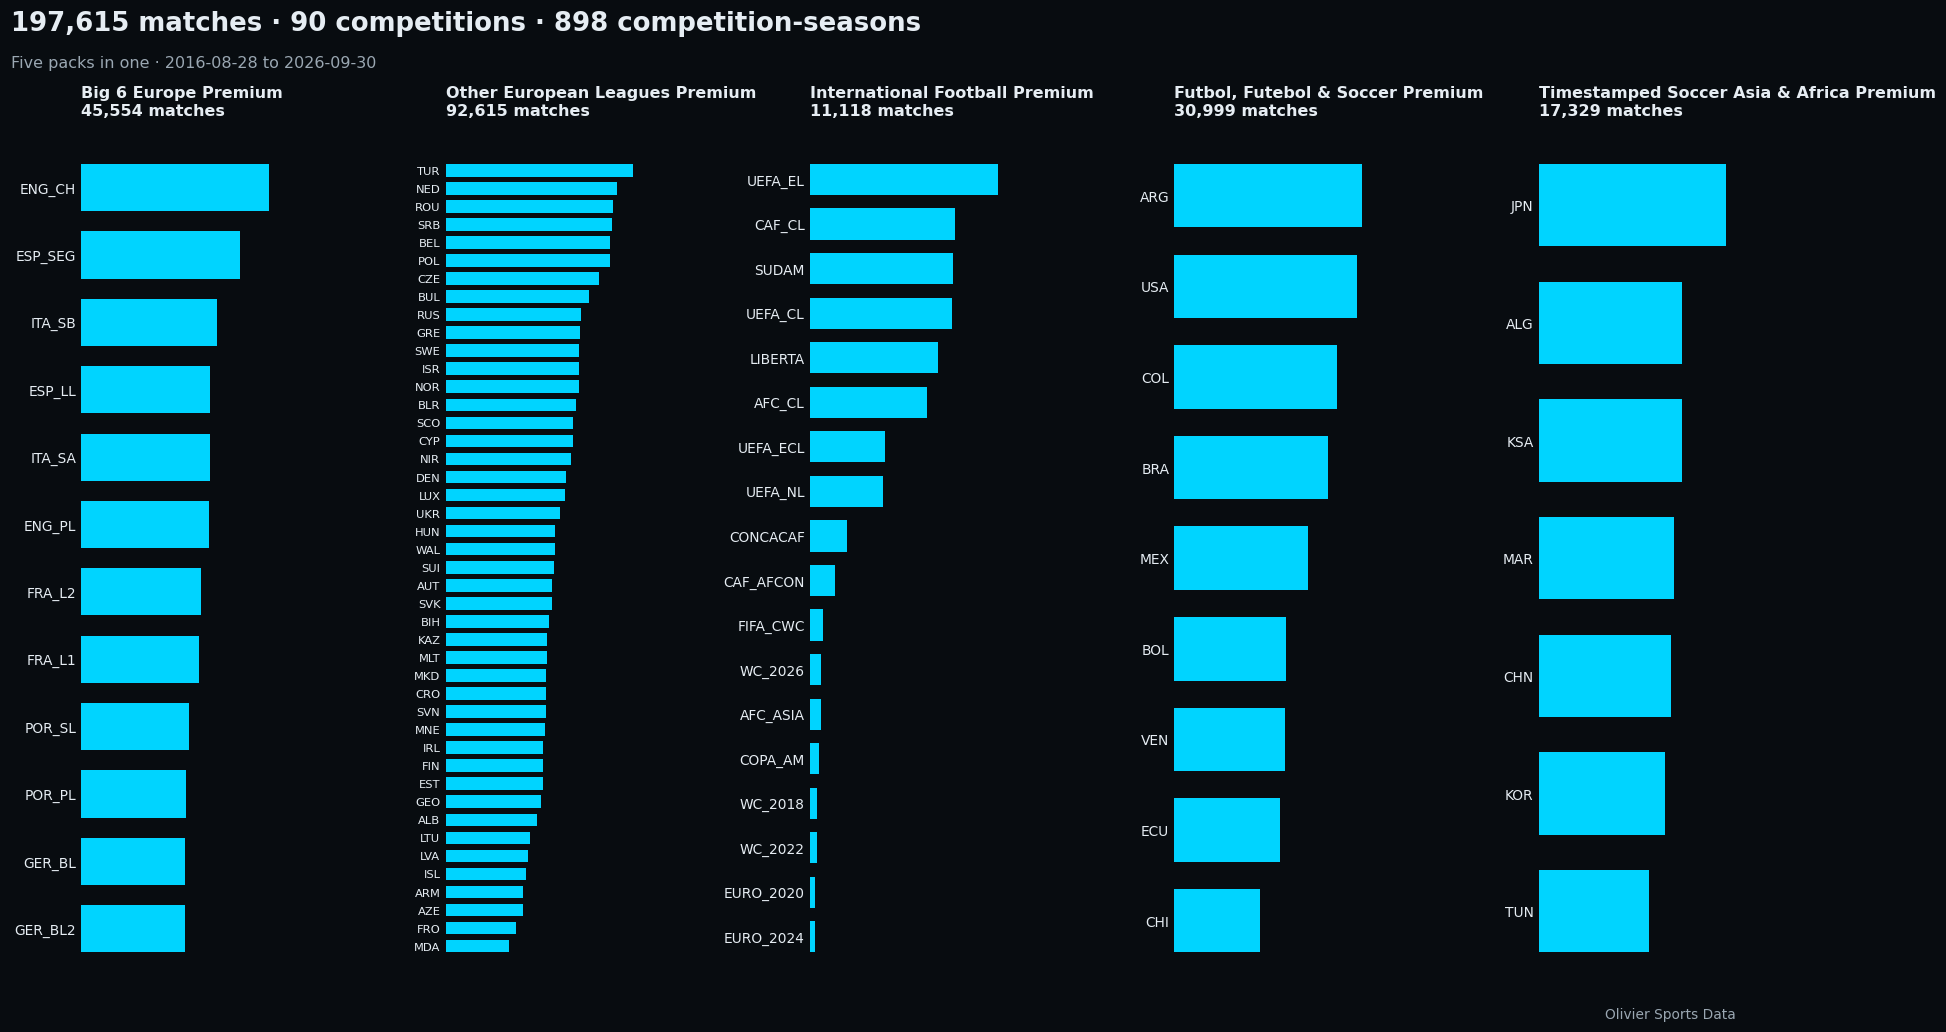

In [5]:
# matches per competition, pack by pack (also saved as a PNG: Output tab on Kaggle)
names = M.drop_duplicates("Competition_Code").set_index("Competition_Code")
fig, axes = plt.subplots(1, len(PACKS), figsize=(16, 9.5), gridspec_kw={"width_ratios": [1] * len(PACKS)})
fig.subplots_adjust(left=0.05, right=0.99, top=0.86, bottom=0.03, wspace=0.85)
for ax, (pack, codes) in zip(axes, PACKS.items()):
    counts = M[M["Pack"] == pack]["Competition_Code"].value_counts().reindex(codes).sort_values()
    ax.barh(range(len(counts)), counts.values, height=0.7, color=CYAN, zorder=2)
    ax.set_yticks(range(len(counts)), counts.index, fontsize=7.5 if len(counts) > 20 else 9, color=FG)
    ax.set_title(f"{pack}\n{counts.sum():,} matches", fontsize=10.5, loc="left")
    ax.xaxis.set_visible(False); ax.grid(False); ax.tick_params(axis="y", length=0)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
fig.text(0.01, 0.95, f"{len(M):,} matches · {M['Competition_Code'].nunique()} competitions · {len(seasons)} competition-seasons",
         fontsize=17, fontweight="bold", color=FG)
fig.text(0.01, 0.915, f"Five packs in one · {M['Kickoff_UTC'].min()[:10]} to {M['Kickoff_UTC'].max()[:10]}",
         fontsize=10.5, color=FG2)
fig.text(0.99, 0.005, "Olivier Sports Data", ha="right", fontsize=9, color=FG2)
fig.savefig("matches_per_competition.png", dpi=150, facecolor=BG)
plt.show()

## 4 · Opening and closing prices

One row per match. For each book and market: the first and the last valid pre-match quote, each with the time
it was recorded. The listing says a closing price is never an in-play price, so every closing time must sit
strictly before the scheduled kickoff.

In [6]:
head = pd.read_csv(os.path.join(ROOT, "Ultimate_Opening_Closing_Odds.csv"), nrows=0).columns
OC = pd.read_csv(os.path.join(ROOT, "Ultimate_Opening_Closing_Odds.csv"), low_memory=False,
                 dtype={c: str for c in head if c.endswith(("_Open_Time", "_Close_Time")) or c in ("Match_ID", "Season", "Country")})
check("one Opening_Closing row per match, same Match_IDs as Matches",
      len(OC) == len(M) and set(OC["Match_ID"]) == set(M["Match_ID"]))
OC = pd.concat([OC, OC["Competition_Code"].map(PACK_OF).rename("Pack")], axis=1)   # 160 columns: one join, no insert
kick = OC["Kickoff_Epoch"].astype("int64")
late, inverted, n_close = 0, 0, 0
for c in [c for c in OC.columns if c.endswith("_Close_Time")]:
    close = epoch(OC[c]); opened = epoch(OC[c.replace("_Close_", "_Open_")])
    n_close += close.notna().sum()
    late += (close >= kick).sum()
    inverted += (opened > close).sum()
check(f"all {n_close:,} closing times are before the scheduled kickoff", late == 0, f"{late} after")
check("opening time <= closing time everywhere", inverted == 0, f"{inverted} inverted")
cov = {b: int(OC[f"{b}_FT_1X2_Close_Time"].notna().sum()) for b in BOOKS}
check("matches with an FT 1X2 close, per book, as listed", cov == CLAIMS["ft_1x2_close_per_book"],
      " · ".join(f"{b} {n:,}" for b, n in cov.items()))
MARKETS8 = ["FT_1X2", "FT_Asian_Handicap", "FT_Total_Goals", "FT_Total_Corners", "HT_1X2", "HT_Asian_Handicap",
            "HT_Total_Goals", "HT_Total_Corners"]
first = {b: {m: OC.loc[OC[f"{b}_{m}_Close_Time"].notna(), "Kickoff_UTC"].min()[:10] for m in MARKETS8
             if f"{b}_{m}_Close_Time" in OC.columns and OC[f"{b}_{m}_Close_Time"].notna().sum() >= 100} for b in BOOKS}
check("markets priced by each book (closing price on at least 100 matches) and the first match of each, as listed",
      first == CLAIMS["first_close_per_market"],
      " · ".join(f"{b}: " + ", ".join(f"{m} {d}" for m, d in v.items()) for b, v in first.items()))

PASS  one Opening_Closing row per match, same Match_IDs as Matches
PASS  all 2,151,699 closing times are before the scheduled kickoff   [0 after]
PASS  opening time <= closing time everywhere   [0 inverted]
PASS  matches with an FT 1X2 close, per book, as listed   [Bet365 191,146 · Pinnacle 145,004 · Unibet 166,824 · Betfair 37,412 · Betsson 73,034]
PASS  markets priced by each book (closing price on at least 100 matches) and the first match of each, as listed   [Bet365: FT_1X2 2016-08-28, FT_Asian_Handicap 2016-08-28, FT_Total_Goals 2016-08-28, FT_Total_Corners 2019-10-13, HT_1X2 2018-01-10, HT_Asian_Handicap 2019-10-13, HT_Total_Goals 2016-12-10, HT_Total_Corners 2016-12-10 · Pinnacle: FT_1X2 2018-09-27, FT_Asian_Handicap 2023-06-23, FT_Total_Goals 2018-09-27 · Unibet: FT_1X2 2017-04-15, FT_Total_Goals 2017-04-15 · Betfair: FT_1X2 2023-11-03 · Betsson: FT_1X2 2022-07-03, FT_Total_Goals 2022-07-03]


### Coverage by pack — share of matches with an FT 1X2 closing price

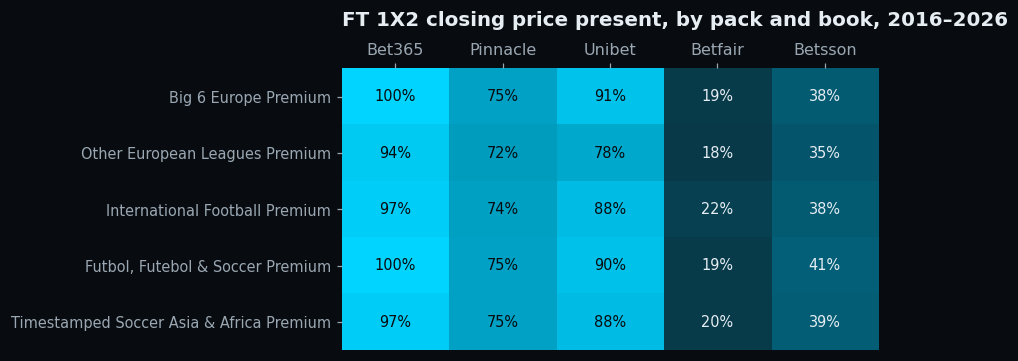

In [7]:
share = pd.DataFrame({b: OC.groupby("Pack")[f"{b}_FT_1X2_Close_Time"].apply(lambda s: s.notna().mean())
                      for b in BOOKS}).reindex(list(PACKS))
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(8.2, 3.4))
ax.imshow(share.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(BOOKS)), BOOKS)
ax.xaxis.tick_top()
ax.set_yticks(range(len(share)), share.index, fontsize=9.5)
ax.grid(False)
for i, p in enumerate(share.index):
    for j, b in enumerate(BOOKS):
        v = share.loc[p, b]
        ax.text(j, i, "–" if v == 0 else f"{v:.0%}", ha="center", va="center", fontsize=9.5,
                color="#080c10" if v > 0.6 else FG)
ax.set_title("FT 1X2 closing price present, by pack and book, 2016–2026", pad=28)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### When is each book in the files?

The README's *Coverage over time* table, recomputed: the share of matches with an FT 1X2 closing price, month by
month, and the same for minute-by-minute statistics and events. A book is measured on the competition-seasons for
which it was collected (an empty cell of its column in `Ultimate_Coverage.csv` means: not collected for that season).
A gap is a month with at least 30 matches in which fewer than half of the matches have it, after the
first month that reaches one half. *Stops for*: a competition with nothing after a date, at least 100 matches later.

PASS  first match with each book (FT 1X2 close), with minute stats and with events, as listed   [Bet365 2016-08-28 · Pinnacle 2018-09-27 · Unibet 2017-04-15 · Betfair 2023-11-03 · Betsson 2022-07-03 · Minute_Stats 2017-06-10 · Events 2016-08-28]
PASS  months with a gap, as listed   [Bet365 none · Pinnacle 2023-09..2023-11, 2026-07..2026-08 · Unibet 2026-07..2026-08 · Betfair 2024-11..2025-08, 2026-07..2026-08 · Betsson 2026-06..2026-08 · Minute_Stats 2018-01..2019-09, 2026-06..2026-07 · Events none]
PASS  competitions where a book, the minute stats or the events stop for good, as listed   [Bet365: BLR 2021-11-28, RUS 2022-03-07 · Unibet: BLR 2021-11-28, MNE 2022-05-20, RUS 2022-03-07 · Minute_Stats: BLR 2021-11-28, RUS 2022-02-28 · Events: BLR 2021-11-28, RUS 2022-02-28]


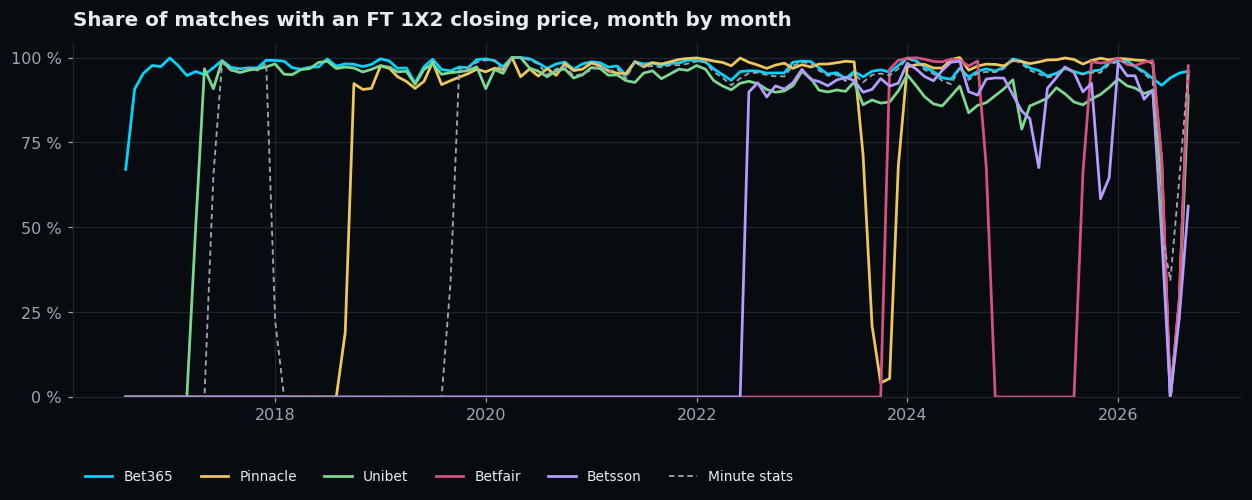

In [8]:
COV = pd.read_csv(os.path.join(ROOT, "Ultimate_Coverage.csv"), dtype={"Season": str})
key = OC["Competition_Code"] + "|" + OC["Season"]
MI = M.set_index("Match_ID").reindex(OC["Match_ID"])
ev_ids = set()
for f in FILES["events"]:
    ev_ids |= set(pd.read_csv(f, usecols=["Match_ID"], dtype=str)["Match_ID"])
month = OC["Kickoff_UTC"].str[:7]
everywhere = np.ones(len(OC), bool)
series = {}
for b in BOOKS:
    collected = set((COV["Competition_Code"] + "|" + COV["Season"])[COV[f"{b}_Pct"].notna()])
    series[b] = (OC[f"{b}_FT_1X2_Close_Time"].notna().to_numpy(), key.isin(collected).to_numpy())
series["Minute_Stats"] = (MI["Has_Minute_Stats"].to_numpy() == 1, everywhere)
series["Events"] = (OC["Match_ID"].isin(ev_ids).to_numpy(), everywhere)
ORDER = sorted(M["Competition_Code"].unique())

def coverage_over_time(present, scope, threshold=0.5, min_matches=30, min_before=50, min_after=100):
    d = pd.DataFrame({"month": month[scope].to_numpy(), "ok": present[scope]})
    first = OC.loc[scope & present, "Kickoff_UTC"].min()[:10]
    g = d.groupby("month")["ok"].agg(["size", "mean"])
    states = [(m, r["mean"] >= threshold) for m, r in g.iterrows() if r["size"] >= min_matches]
    while states and not states[0][1]:
        states.pop(0)
    gaps, cur = [], None
    for m, ok in states:
        if not ok:
            cur = [m, m] if cur is None else [cur[0], m]
        elif cur:
            gaps.append(cur); cur = None
    if cur:
        gaps.append(cur)
    stops = {}
    comp = OC["Competition_Code"].to_numpy()
    for c in ORDER:
        sel = scope & (comp == c)
        mine = OC.loc[sel]
        hit = mine.loc[present[sel], "Kickoff_UTC"]
        if len(hit) >= min_before and (mine["Kickoff_UTC"] > hit.max()).sum() >= min_after:
            stops[c] = hit.max()[:10]
    return first, gaps, stops, g["mean"]

timeline, got_from, got_gaps, got_stops = {}, {}, {}, {}
for name, (present, scope) in series.items():
    got_from[name], got_gaps[name], got_stops[name], timeline[name] = coverage_over_time(present, scope)
check("first match with each book (FT 1X2 close), with minute stats and with events, as listed",
      got_from == CLAIMS["coverage_from"], " · ".join(f"{k} {v}" for k, v in got_from.items()))
check("months with a gap, as listed", got_gaps == CLAIMS["coverage_gaps"],
      " · ".join(f"{k} " + (", ".join(a if a == b else f"{a}..{b}" for a, b in v) or "none") for k, v in got_gaps.items()))
check("competitions where a book, the minute stats or the events stop for good, as listed",
      got_stops == CLAIMS["coverage_stops"],
      " · ".join(f"{k}: " + ", ".join(f"{c} {d}" for c, d in v.items()) for k, v in got_stops.items() if v) or "none")

fig, ax = plt.subplots(figsize=(11.5, 4.8))
for name in BOOKS:
    s = timeline[name]
    ax.plot(pd.to_datetime(s.index), s.values, color=BOOK_COLOR[name], linewidth=1.8, label=name)
s = timeline["Minute_Stats"]
ax.plot(pd.to_datetime(s.index), s.values, color=FG2, linewidth=1.2, linestyle=(0, (3, 2)), label="Minute stats")
ax.set_ylim(0, 1.04)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0 %", "25 %", "50 %", "75 %", "100 %"])
ax.set_title("Share of matches with an FT 1X2 closing price, month by month", pad=12)
ax.legend(loc="lower left", ncol=6, fontsize=9, bbox_to_anchor=(0, -0.28))
plt.tight_layout(); plt.show()

### How close to kickoff is a "closing" price?

A closing quote is the last pre-match price the book published. Books update at different rhythms, so each one
gets its own closing time. Below: median and interquartile range of the gap to kickoff, FT 1X2.

PASS  median closing gap per book, as listed   [Pinnacle 4 min · Betfair 6 min · Betsson 10 min · Bet365 25 min · Unibet 1.8 h]


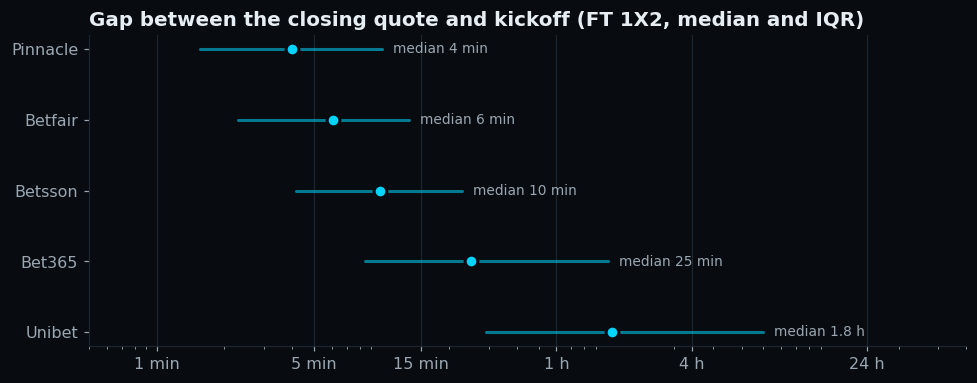

In [9]:
def upper_median(v):
    v = np.sort(np.asarray(v)); return v[len(v) // 2]

def readable(s):
    return f"{s / 3600:.1f} h" if s >= 5400 else f"{s / 60:.0f} min"

gaps = {}
for b in BOOKS:
    g = (kick - epoch(OC[f"{b}_FT_1X2_Close_Time"])).dropna().to_numpy()
    gaps[b] = g
got = {b: readable(upper_median(g)) for b, g in gaps.items()}
check("median closing gap per book, as listed", all(got[b] == CLAIMS["median_close_gap"][b] for b in BOOKS),
      " · ".join(f"{b} {got[b]}" for b in sorted(got, key=lambda b: upper_median(gaps[b]))))

books = sorted(BOOKS, key=lambda b: upper_median(gaps[b]), reverse=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, b in enumerate(books):
    q1, q2, q3 = np.percentile(gaps[b] / 60, [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2, solid_capstyle="round", alpha=0.55)
    ax.scatter([q2], [i], s=70, color=CYAN, zorder=3, edgecolor=BG, linewidth=2)
    ax.text(q3 * 1.12, i, f"median {readable(upper_median(gaps[b]))}", va="center", fontsize=9, color=FG2)
ax.set_xscale("log")
ax.set_xticks([1, 5, 15, 60, 240, 1440], ["1 min", "5 min", "15 min", "1 h", "4 h", "24 h"])
ax.set_yticks(range(len(books)), books)
ax.set_xlim(0.5, 4000)
ax.grid(axis="y", visible=False)
ax.set_title("Gap between the closing quote and kickoff (FT 1X2, median and IQR)")
plt.tight_layout(); plt.show()

### Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict results
better. Probabilities are de-margined proportionally; lower log-loss is better. Compare open and close **within a
book** — books cover different sets of matches, so the rows are not comparable with each other.

In [10]:
y = OC["Result_90"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
rows = []
for b in BOOKS:
    cols = lambda k: [f"{b}_FT_1X2_{k}_{s}" for s in ("Home", "Draw", "Away")]
    o, c = OC[cols("Open")].to_numpy(float), OC[cols("Close")].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    def logloss(x):
        p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
        return -np.log(p[np.arange(ok.sum()), y[ok]]).mean()
    rows.append((b, ok.sum(), logloss(o), logloss(c), (1 / o[ok]).sum(1).mean() - 1, (1 / c[ok]).sum(1).mean() - 1))
LL = pd.DataFrame(rows, columns=["Book", "Matches", "LogLoss open", "LogLoss close", "Margin open", "Margin close"]).set_index("Book")
check("closing beats opening on log-loss, for every book", (LL["LogLoss close"] < LL["LogLoss open"]).all())
LL.style.format({"Matches": "{:,}", "LogLoss open": "{:.4f}", "LogLoss close": "{:.4f}",
                 "Margin open": "{:.2%}", "Margin close": "{:.2%}"})

PASS  closing beats opening on log-loss, for every book


,Matches,LogLoss open,LogLoss close,Margin open,Margin close
Book,,,,,
Bet365,"191,146",0.9877,0.9762,8.53%,7.43%
Pinnacle,"145,004",0.9862,0.9764,6.17%,4.51%
Unibet,"166,824",0.9868,0.9796,8.41%,8.22%
Betfair,"37,412",0.9891,0.9779,8.85%,11.40%
Betsson,"73,034",0.9839,0.9781,7.10%,7.10%


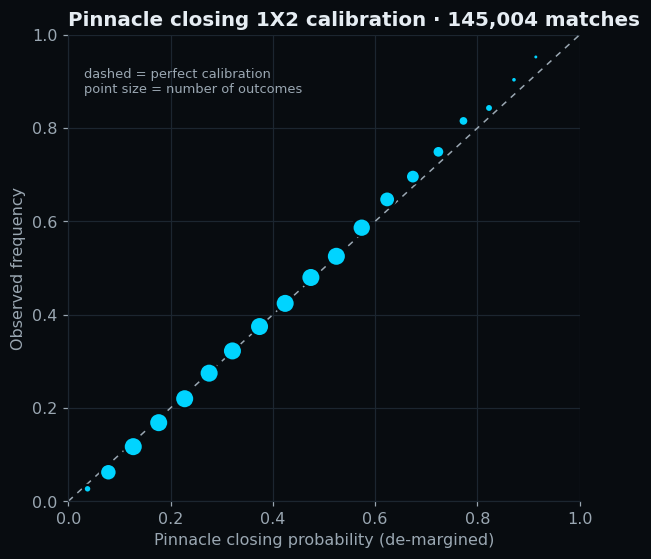

In [11]:
# Pinnacle closing 1X2: predicted probability vs observed frequency (all three outcomes pooled)
cols = [f"Pinnacle_FT_1X2_Close_{s}" for s in ("Home", "Draw", "Away")]
x = OC[cols].to_numpy(float); ok = ~np.isnan(x).any(1)
p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
hit = np.zeros_like(p); hit[np.arange(ok.sum()), y[ok]] = 1
cal = pd.DataFrame({"p": p.ravel(), "hit": hit.ravel()})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 50]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 100, 12, 160), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability (de-margined)"); ax.set_ylabel("Observed frequency")
ax.set_title(f"Pinnacle closing 1X2 calibration · {ok.sum():,} matches")
ax.text(0.03, 0.93, "dashed = perfect calibration\npoint size = number of outcomes", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 5 · 354 million timestamped quotes

One pass over the 90 odds files, a few columns at a time. Checked on every row: a **pre-match** quote carries no
score and was recorded before the scheduled kickoff.

In [12]:
kick_by_id = pd.Series(M["Kickoff_Epoch"].to_numpy("int64"), index=M["Match_ID"].astype("int64"))
pack_by_id = pd.Series(M["Pack"].to_numpy(), index=M["Match_ID"].astype("int64"))
use = ["Match_ID", "Book", "Phase", "Epoch", "Score_Home"]
t0 = time.time()
by_book_phase, by_book_pack = [], []
pre_scored = pre_late = n_rows = 0
off_manifest = []
for i, f in enumerate(FILES["odds"], 1):
    d = read(f, use)
    n_rows += len(d)
    if len(d) != ROWS.get(stem(f)):
        off_manifest.append(stem(f))
    pre = (d["Phase"] == "Pre-match").to_numpy()
    pre_scored += (pre & d["Score_Home"].notna().to_numpy()).sum()
    pre_late += (pre & (d["Epoch"].to_numpy() >= kick_by_id.reindex(d["Match_ID"]).to_numpy())).sum()
    by_book_phase.append(d.groupby(["Book", "Phase"]).size())
    by_book_pack.append(d.groupby([d["Book"], pack_by_id.reindex(d["Match_ID"]).to_numpy()]).size())
    if i % 15 == 0 or i == len(FILES["odds"]):
        print(f"{i:>2} / {len(FILES['odds'])} files   {n_rows:>13,} quotes   {time.time() - t0:5.0f} s")
    del d

bp = pd.concat(by_book_phase).groupby(level=[0, 1]).sum().unstack(fill_value=0)
phase = bp.sum()
check(f"{CLAIMS['quotes']:,} quotes, every file equal to the MANIFEST", n_rows == CLAIMS["quotes"] and not off_manifest,
      f"{n_rows:,}" + (f", off: {', '.join(off_manifest)}" if off_manifest else ""))
check("in-play / pre-match split as listed",
      phase.get("In-play", 0) == CLAIMS["in_play"] and phase.get("Pre-match", 0) == CLAIMS["pre_match"],
      f"{phase.get('In-play', 0):,} in-play · {phase.get('Pre-match', 0):,} pre-match")
check("quotes per book as listed", {b: int(n) for b, n in bp.sum(axis=1).items()} == CLAIMS["quotes_per_book"])
check("no pre-match quote carries a score", pre_scored == 0, f"{pre_scored}")
check("every pre-match quote is before the scheduled kickoff", pre_late == 0, f"{pre_late}")
bp.assign(Total=bp.sum(axis=1)).reindex(BOOKS).style.format("{:,}")

15 / 90 files      55,106,698 quotes      54 s
30 / 90 files     134,089,740 quotes     140 s
45 / 90 files     181,146,427 quotes     184 s
60 / 90 files     242,356,843 quotes     253 s
75 / 90 files     300,712,613 quotes     310 s
90 / 90 files     353,573,942 quotes     366 s
PASS  353,573,942 quotes, every file equal to the MANIFEST   [353,573,942]
PASS  in-play / pre-match split as listed   [263,916,151 in-play · 89,657,791 pre-match]
PASS  quotes per book as listed
PASS  no pre-match quote carries a score   [0]
PASS  every pre-match quote is before the scheduled kickoff   [0]


Phase,In-play,Pre-match,Total
Book,,,
Bet365,"222,970,426","27,635,646","250,606,072"
Pinnacle,"1,216,695","15,960,343","17,177,038"
Unibet,"21,516,647","1,746,451","23,263,098"
Betfair,"12,766,710","41,367,777","54,134,487"
Betsson,"5,445,673","2,947,574","8,393,247"


Quotes per match, all markets, by pack: how often each book updated its prices.

In [13]:
bk = pd.concat(by_book_pack).groupby(level=[0, 1]).sum().unstack(level=0, fill_value=0).reindex(index=list(PACKS), columns=BOOKS)
(bk.div(M.groupby("Pack").size().reindex(list(PACKS)), axis=0)).round(0).astype(int)

Book,Bet365,Pinnacle,Unibet,Betfair,Betsson
Big 6 Europe Premium,1308,116,132,315,47
Other European Leagues Premium,1012,69,89,223,33
International Football Premium,1884,144,172,335,68
"Futbol, Futebol & Soccer Premium",1732,83,162,347,53
Timestamped Soccer Asia & Africa Premium,1308,75,120,268,44


### Other bookmakers, lineups, events, minute-by-minute stats

Rows counted from the files themselves, and every row must join a match of `Ultimate_Matches` on `Match_ID`.

In [14]:
ids = set(M["Match_ID"].astype("int64"))
parts, off = [], []
for f in FILES["snapshots"]:
    d = read(f, ["Match_ID", "Book", "Snapshot", "Minutes_Before_Kickoff"])
    if len(d) != ROWS.get(stem(f)):
        off.append(stem(f))
    parts.append(d)
S = pd.concat(parts, ignore_index=True); del parts
check(f"{CLAIMS['snapshots']:,} snapshot rows, all joined to a match", len(S) == CLAIMS["snapshots"] and S["Match_ID"].isin(ids).all()
      and not off, f"{len(S):,}" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
check(f"{CLAIMS['snapshot_books']} bookmakers, none of the 5 main books",
      S["Book"].nunique() == CLAIMS["snapshot_books"] and not set(S["Book"]) & set(BOOKS + ["Betfair (Sportsbook)"]),
      f"{S['Book'].nunique()} books")
check("every snapshot is pre-match (Minutes_Before_Kickoff >= 0)", (S["Minutes_Before_Kickoff"] >= 0).all())
per_match = S.groupby("Match_ID")["Book"].nunique()
check(f"{CLAIMS['snapshot_matches']:,} matches with snapshots, {CLAIMS['snapshot_books_per_match']} bookmakers per match "
      "on average", len(per_match) == CLAIMS["snapshot_matches"]
      and round(per_match.mean(), 1) == CLAIMS["snapshot_books_per_match"], f"{len(per_match):,}, {per_match.mean():.1f}")
del S

timed, untimed, rows_untimed, event_types = set(), set(), 0, set()
for folder in ("lineups", "events", "minute_stats"):
    n, orphans, off = 0, 0, []
    for f in FILES[folder]:
        d = read(f, {"minute_stats": ["Match_ID", "Timestamp_UTC"], "events": ["Match_ID", "Event_Type"]}.get(folder, ["Match_ID"]))
        if folder == "events":
            event_types |= set(d["Event_Type"].dropna())
        if folder == "minute_stats":
            has = d["Timestamp_UTC"].notna()
            timed |= set(d.loc[has, "Match_ID"]); untimed |= set(d.loc[~has, "Match_ID"])
            rows_untimed += int((~has).sum())
        n += len(d)
        orphans += (~d["Match_ID"].isin(ids)).sum()
        if len(d) != ROWS.get(stem(f)):
            off.append(stem(f))
    check(f"{CLAIMS[folder]:,} {folder.replace('_', ' ')} rows, all joined to a match", n == CLAIMS[folder] and orphans == 0 and not off,
          f"{n:,} rows, {orphans} without a match" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
check(f"{CLAIMS['event_types']} event types", len(event_types) == CLAIMS["event_types"], ", ".join(sorted(event_types)))
share = (M.groupby("Pack")["Has_Lineups"].mean() * 100).round().astype(int).to_dict()
check("share of matches with both starting elevens, per pack, as listed", share == CLAIMS["lineups_share_per_pack"],
      " · ".join(f"{p} {v} %" for p, v in share.items()))
kick_utc = M.set_index(M["Match_ID"].astype("int64"))["Kickoff_UTC"]
first_timed = kick_utc.reindex(list(timed)).min()
T = CLAIMS["minute_stats_time"]
check(f"minute-by-minute statistics carry their recording time from {T['from']}; "
      f"{T['matches_without']:,} matches and {T['rows_without']:,} rows without it",
      first_timed[:10] == T["from"] and len(untimed) == T["matches_without"] and rows_untimed == T["rows_without"]
      and (not T["clean_border"] or (not (timed & untimed) and kick_utc.reindex(list(untimed)).max() < first_timed)),
      f"first {first_timed[:10]}; {len(untimed):,} matches and {rows_untimed:,} rows without time")

PASS  10,835,875 snapshot rows, all joined to a match   [10,835,875]
PASS  37 bookmakers, none of the 5 main books   [37 books]
PASS  every snapshot is pre-match (Minutes_Before_Kickoff >= 0)
PASS  188,855 matches with snapshots, 13.9 bookmakers per match on average   [188,855, 13.9]
PASS  5,478,267 lineups rows, all joined to a match   [5,478,267 rows, 0 without a match]
PASS  5,220,292 events rows, all joined to a match   [5,220,292 rows, 0 without a match]
PASS  49,494,435 minute stats rows, all joined to a match   [49,494,435 rows, 0 without a match]
PASS  13 event types   [Assist, Corner, Goal, Missed Penalty, Offside, Penalty Shootout Missed, Penalty Shootout Scored, Race To Corners, Red Card, Shot Off Target, Shot On Target, Substitution, Yellow Card]
PASS  share of matches with both starting elevens, per pack, as listed   [Big 6 Europe Premium 98 % · Futbol, Futebol & Soccer Premium 79 % · International Football Premium 85 % · Other European Leagues Premium 55 % · Timestamped S

## 6 · One match, quote by quote

The match shown in the listing: PSG 1-1 Arsenal, Champions League final, Budapest,
30 May 2026. Arsenal scored early, PSG equalised in the second half, extra time stayed 1-1 and PSG won the shoot-out
4-3. Bet365 full-time 1X2 in play (the 90-minute market), recomputed here from
`Ultimate_Odds_Timestamped_UEFA_CL.csv.gz`, then drawn as implied probabilities, with the goals of the events table on
top. Clocks are delivered as the bookmaker sent them, never adjusted.

In [15]:
MID = 11854567
row = M[M["Match_ID"] == str(MID)].iloc[0]
check("the Matches row: PSG 0-1 at half-time, 1-1 after 90 minutes and after extra time, shoot-out 4-3, final, "
      "neutral venue",
      (row["Home_Goals_HT"], row["Away_Goals_HT"], row["Home_Goals_90"], row["Away_Goals_90"], row["Extra_Time"],
       row["Home_Goals_AET"], row["Away_Goals_AET"], row["Home_Penalties"], row["Away_Penalties"], row["Stage"],
       row["Neutral_Venue"])
      == (0, 1, 1, 1, 1, 1, 1, 4, 3, "Final", 1))
cols = ["Match_ID", "Book", "Market", "Phase", "Timestamp_UTC", "Epoch", "Minute",
        "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]
ucl = read(next(f for f in FILES["odds"] if stem(f).endswith("_UEFA_CL")), cols)
one = ucl[ucl["Match_ID"] == MID]
del ucl
print(one.groupby(["Book", "Phase"]).size().unstack(fill_value=0))
check(f"{CLAIMS['example_quotes_all_books']:,} quotes from the 5 books on this match",
      len(one) == CLAIMS["example_quotes_all_books"], f"{len(one):,}")
t = one[(one["Book"] == "Bet365") & (one["Market"] == "FT_1X2") & (one["Phase"] == "In-play")].sort_values("Epoch", kind="stable")
t = t.reset_index(drop=True)
check(f"{CLAIMS['example_in_play_bet365_1x2']} in-play Bet365 1X2 quotes on this match",
      len(t) == CLAIMS["example_in_play_bet365_1x2"], f"{len(t)}")
pre = one[one["Phase"] == "Pre-match"]
check("every pre-match quote is before the scheduled kickoff (" + row["Kickoff_UTC"][11:16] + " UTC)",
      (pre["Epoch"] < row["Kickoff_Epoch"]).all())

# the listing's rule: around each score change, the quote before and the quote at the change
keep, last = [], None
for i, sc in enumerate(zip(t["Score_Home"].fillna(-1), t["Score_Away"].fillna(-1))):
    if sc != last:
        keep += [k for k in (i - 1, i) if k >= 0 and k not in keep]
        last = sc
show = (t.loc[keep, ["Timestamp_UTC", "Minute", "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]]
          .astype({"Minute": "Int64", "Score_Home": "Int64", "Score_Away": "Int64"}))
show

PASS  the Matches row: PSG 0-1 at half-time, 1-1 after 90 minutes and after extra time, shoot-out 4-3, final, neutral venue
Phase     In-play  Pre-match
Book                        
Bet365       1317        420
Betfair       195         34
Betsson       197         46
Pinnacle        0        479
Unibet        434         85
PASS  3,207 quotes from the 5 books on this match   [3,207]
PASS  168 in-play Bet365 1X2 quotes on this match   [168]
PASS  every pre-match quote is before the scheduled kickoff (16:00 UTC)


,Timestamp_UTC,Minute,Score_Home,Score_Away,Price_Home,Price_Draw,Price_Away,Suspended
0,2026-05-30T16:02:40Z,<NA>,0,0,2.40,3.250,2.900,0
14,2026-05-30T16:07:06Z,5,0,0,NaN,NaN,NaN,1
15,2026-05-30T16:07:08Z,5,0,1,4.75,3.400,1.800,0
93,2026-05-30T17:29:11Z,64,0,1,7.50,3.500,1.571,0
94,2026-05-30T17:29:33Z,64,1,1,3.20,1.909,4.500,0


 Minute  Added_Time Event_Type Team_Side  Player
      6        <NA>       Goal      Away Havertz
     65        <NA>       Goal      Home Dembele
Team_Side  Event_Type             
Away       Penalty Shootout Missed    2
           Penalty Shootout Scored    3
Home       Penalty Shootout Missed    1
           Penalty Shootout Scored    4


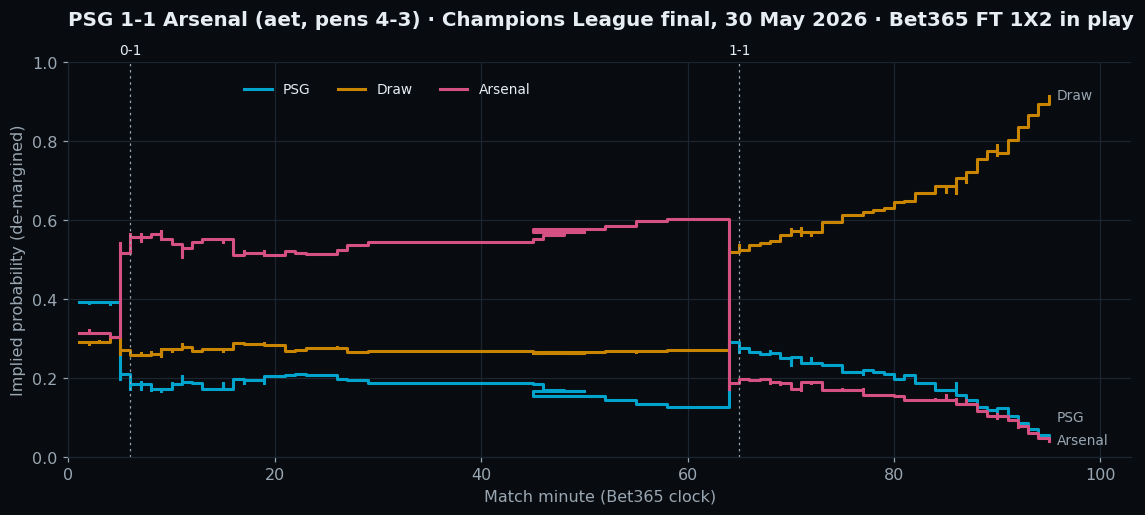

In [16]:
ev = read(next(f for f in FILES["events"] if stem(f).endswith("_UEFA_CL")),
          ["Match_ID", "Minute", "Added_Time", "Event_Type", "Team_Side", "Player"])
mine = ev[(ev["Match_ID"] == MID)]
goals = mine[mine["Event_Type"] == "Goal"].sort_values(["Minute", "Added_Time"], na_position="first")
print(goals[["Minute", "Added_Time", "Event_Type", "Team_Side", "Player"]]
      .astype({"Minute": "Int64", "Added_Time": "Int64"}).to_string(index=False))
print(mine[mine["Event_Type"].str.startswith("Penalty Shootout")].groupby(["Team_Side", "Event_Type"]).size().to_string())

live = t[(t["Suspended"] == 0) & t["Minute"].notna()].copy()
inv = 1 / live[["Price_Home", "Price_Draw", "Price_Away"]]
prob = inv.div(inv.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = live["Minute"]
names_hda = {"Price_Home": "PSG", "Price_Draw": "Draw", "Price_Away": "Arsenal"}
for col, side in zip(prob.columns, ["Home", "Draw", "Away"]):
    ax.plot(x, prob[col], color=HDA[side], linewidth=2, label=names_hda[col], drawstyle="steps-post")
ends = sorted((prob[col].iloc[-1], col) for col in prob.columns)      # bottom up
y_lab = []
for v, col in ends:                                   # end labels at least 0.06 apart, inside the axes
    y_lab.append(min(0.97, max(v, 0.03, y_lab[-1] + 0.06 if y_lab else 0.03)))
    ax.text(x.iloc[-1] + 0.8, y_lab[-1], names_hda[col], color=FG2, fontsize=9, va="center")
score_h = score_a = 0
for _, g in goals.iterrows():
    m = g["Minute"] + (0 if pd.isna(g["Added_Time"]) else g["Added_Time"])
    if m > 95:
        continue                                      # extra time: after the 90-minute market
    score_h += g["Team_Side"] == "Home"; score_a += g["Team_Side"] == "Away"
    ax.axvline(m, color=FG2, linewidth=0.8, linestyle=(0, (2, 3)))
    ax.text(m, 1.02, f"{score_h}-{score_a}", ha="center", fontsize=9, color=FG, transform=ax.get_xaxis_transform())
ax.set_ylim(0, 1); ax.set_xlim(0, max(97, x.max() + 8))
ax.set_xlabel("Match minute (Bet365 clock)"); ax.set_ylabel("Implied probability (de-margined)")
ax.set_title("PSG 1-1 Arsenal (aet, pens 4-3) · Champions League final, 30 May 2026 · Bet365 FT 1X2 in play",
             pad=24)
ax.legend(loc="upper center", bbox_to_anchor=(0.3, 0.98), ncol=3, fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

## 7 · Nothing a spreadsheet can reinterpret

Formations are digits (4231 = 4-2-3-1), timestamps carry the T and the Z, seasons read 2016/17 or 2019, and no
text cell starts with a character a spreadsheet would read as a formula or turn into a date.

In [17]:
iso = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$")
risky = re.compile(r"^([=+@\-]|\d{1,2}[-/]\d{1,2}([-/]\d{2,4})?$|\d{1,2}:\d{2}(:\d{2})?$)")
form = pd.concat([M["Home_Formation"], M["Away_Formation"]]).dropna()
check("formations are digits that add up to 10 players",
      form.str.fullmatch(r"\d{3,5}").all() and form.map(lambda s: sum(map(int, s)) == 10).all(),
      f"{len(form):,} formations, e.g. {form.value_counts().index[0]}")
times = pd.concat([M["Kickoff_UTC"]] + [OC[c].dropna() for c in OC.columns if c.endswith(("_Open_Time", "_Close_Time"))])
check("every timestamp is ISO 8601 with T and Z", times.map(lambda s: bool(iso.match(s))).all(), f"{len(times):,} cells")
TS = pd.read_csv(os.path.join(ROOT, "Ultimate_Team_Stats.csv"), dtype=str)
is_text = lambda s: s.dtype == object or isinstance(s.dtype, pd.StringDtype)
text_cells = pd.concat([df[c].dropna().astype(str) for df in (M.drop(columns="Pack"), OC.drop(columns="Pack"), TS)
                        for c in df.columns if is_text(df[c]) and not c.endswith(("_Open_Time", "_Close_Time", "_UTC"))])
bad = text_cells[text_cells.map(lambda s: bool(risky.match(s)))]
check("no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)", bad.empty,
      f"{len(text_cells):,} text cells" + (f", e.g. {bad.iloc[0]!r}" if len(bad) else ""))
check(f"{CLAIMS['team_stats']:,} team-stat rows, two per match", len(TS) == CLAIMS["team_stats"] == 2 * len(M))
check(f"{CLAIMS['team_stat_metrics']} team statistics per row", TS.shape[1] - 4 == CLAIMS["team_stat_metrics"],
      f"{TS.shape[1] - 4}")

PASS  formations are digits that add up to 10 players   [153,407 formations, e.g. 4231]
PASS  every timestamp is ISO 8601 with T and Z   [4,501,013 cells]
PASS  no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)   [15,136,936 text cells]
PASS  395,230 team-stat rows, two per match
PASS  29 team statistics per row   [29]


## 8 · Summary

In [18]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

49 / 49 claims verified


Result,Claim,Detail
PASS,all 459 files present,
PASS,every SHA-256 matches the MANIFEST (files kept compressed),
PASS,"197,615 matches","197,615"
PASS,Match_ID is unique across the five packs,
PASS,every competition belongs to one of the five packs,
PASS,90 competitions: 72 domestic leagues in 66 countries (6 second divisions) and 18 international competitions; 898 competition-seasons,"(90, 72, 66, 6, 18) / 898"
PASS,"matches per pack, as listed","Other European Leagues Premium 92,615 · Big 6 Europe Premium 45,554 · Futbol, Futebol & Soccer Premium 30,999 · Timestamped Soccer Asia & Africa Premium 17,329 · International Football Premium 11,118"
PASS,"matches per competition, as listed",
PASS,"first kickoff on 2016-08-28, last before 2026-10-01",2016-08-28T00:00:00Z to 2026-09-30T23:30:00Z
PASS,Season reads 2016/17 (two calendar years) or 2019 (one),"2016, 2016/17, 2017, 2017/18..."


---

Everything above ran on the files a buyer downloads. The README in the ZIP holds the full column dictionary,
the coverage tables (by competition, by book, over time), and one chapter per pack: seasons and stages, knockout
rules, the removed source events with their evidence, and every known limitation.

👉 ⚽ **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/ylkgqx?utm_source=github&utm_medium=notebook&utm_campaign=all_in_one_premium&utm_content=notebook_bottom)** 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*